**Recommendation System**


set up and loading the model and the clean dataset

In [ ]:
#Nourah added this and its work can we remove the above ??

import pandas as pd
import joblib
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project folder
ROOT = Path.cwd() if (Path.cwd()/'models').exists() else Path.cwd().parent

# Load the selected model (Random Forest) and the cleaned dataset
model = joblib.load(ROOT/'/content/best_model.joblib')
df = pd.read_parquet(ROOT/'/content/clean_crop.parquet')


print(model)
print(len(model.classes_), "crops,", df.shape)
FEATURES = ["nitrogen", "phosphorus", "potassium", "temperature", "humidity", "ph", "rainfall"]


RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
22 crops, (2200, 8)


The recommendation function with input validation

In [ ]:
#the recomment_crop function takes environment and soil conditions to predict which crop is most suitable
def recommend_crop(nitrogen,phosphorus,potassium,temperature,humidity,ph,rainfall):
  #validating input type -- makes sure they fall within the training dataset ranges
  for value in [nitrogen,phosphorus,potassium,temperature,humidity,ph,rainfall]:
    if not isinstance(value,(int,float)):
      raise ValueError('All inputs must be numbers, you entered '+str(value))
  #validating inputs range
  if humidity<0 or humidity>100:
   raise ValueError("humidity must be between 0 and 100")
  if ph<0 or ph>14:
   raise ValueError("ph must be between 0 and 14")
  if nitrogen<0 or phosphorus<0 or potassium<0 or rainfall<0:
    raise ValueError("value can not be negative")
  feature_values={"nitrogen":nitrogen, "phosphorus":phosphorus, "potassium":potassium, "temperature":temperature, "humidity":humidity, "ph":ph, "rainfall":rainfall}
  for feature in FEATURES:
    if feature_values[feature]<df[feature].min() or feature_values[feature]>df[feature].max():
       print('warning: ',feature,'is outside the range of training data')
  #prepare input for the model
  X=pd.DataFrame([feature_values])[FEATURES]
  #probs --> predict probability for each crop
  probs = pd.Series(model.predict_proba(X)[0] * 100, index=model.classes_) #ask the trained model to calculate the probability for each crop class
  #top3 selects the highest 3 probabilities
  top3 = probs.sort_values(ascending=False).head(3).round(3)
  return top3



Testing valid inputs and invalid inputs


In [ ]:
#testing valid inputs
#recommend_crop(nitrogen,phosphorus,potassium,temperature,humidity,ph,rainfall) takes these values in this order
print(recommend_crop(90, 42, 43, 21, 82, 6.5, 203))
print(recommend_crop(70,53,39,31,77,7.9,302))

#testing invalid inputs(range)
try:
   print(recommend_crop(90, 42, 43, 21, 130, 6.5, 203))
except ValueError as e:
   print('caught:', e)
#testing invalid inputs(type)
try:
  print(recommend_crop("a lot", 42, 43, 21, 80, 6.5, 200))
except ValueError as e:
  print('caught:', e)

try:
  print(recommend_crop(70,53,39,31,77,-8,302))

except ValueError as e:
  print('caught:', e)

print(recommend_crop(90, 42, 43, 21, 82, 6.5, 400))

rice         93.5
jute          6.5
blackgram     0.0
dtype: float64
rice      41.0
jute      26.0
papaya    16.5
dtype: float64
caught: humidity must be between 0 and 100
caught: All inputs must be numbers, you entered a lot
caught: ph must be between 0 and 14
rice         96.5
jute          3.5
blackgram     0.0
dtype: float64


**The rainfall what if experiment **
due to various enviromental conditions water is now a less relaiable source, therefore we have to test what if the crops receive less rain

In [ ]:
#calculate the median of each crop since its not affected by outliers
profiles = df.groupby("label", observed=True)[FEATURES].median()
profiles.loc["rice"]#showing the typical(median) rice row


,rice
nitrogen,80.000000
phosphorus,47.000000
potassium,40.000000
temperature,23.734837
humidity,82.189354
ph,6.363803
rainfall,233.119858


In [ ]:
#expermenting on different crops
crops = ["rice", "coffee", "orange", "maize", "chickpea"] #choose the crops to investigate
results = []

#loop through each crop
for crop in crops:
 r = profiles.loc[crop]
 #simulate different rainfall amounts
 for rain in range(25, 300, 25):
  #predict the top3 crops for each scenario
   top3 = recommend_crop(float(r["nitrogen"]), float(r["phosphorus"]), float(r["potassium"]), float(r["temperature"]), float(r["humidity"]), float(r["ph"]), rain)
   #store the results
   results.append({"crop": crop, "rainfall": rain,"recommended": top3.index[0], "confidence": top3.iloc[0],"originalcrop_prob":top3.get(crop,0)})
whatif = pd.DataFrame(results)
#create a comparison table with pivot
whatif.pivot(index="rainfall", columns="crop", values="recommended")

crop,chickpea,coffee,maize,orange,rice
rainfall,,,,,
25,chickpea,muskmelon,maize,orange,muskmelon
50,chickpea,coffee,maize,orange,watermelon
75,chickpea,coffee,maize,orange,jute
100,chickpea,coffee,maize,orange,jute
125,chickpea,coffee,maize,orange,jute
150,chickpea,coffee,maize,orange,jute
175,chickpea,coffee,maize,orange,jute
200,chickpea,coffee,maize,orange,rice
225,chickpea,coffee,maize,orange,rice


The results of the experiments above show how crop type varies if we change rainfall and keep other environmental conditions stable.

we can interpret form these results:
*   Chickpea is highly stable
*   coffee stable after thelowest rainfall scenario (25)
*   Miaze highly stable
*   Orange highly stable
*   Rice very sensitive to rainfall ammount as rice is only recommended at the highest rainfall scenarios





Visualizing the rainfall experiment

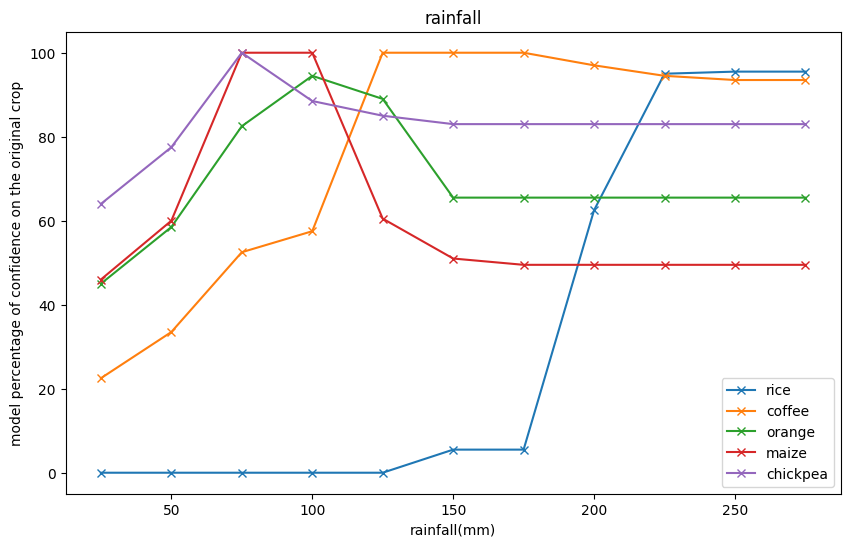

In [ ]:
plt.figure(figsize=(10,6))
for crop in crops:#to represent each crop with one line
  crop_row=whatif[whatif['crop']==crop]
  plt.plot(crop_row['rainfall'],crop_row['originalcrop_prob'],marker='x',label=crop)

plt.xlabel('rainfall(mm)')
plt.ylabel('model percentage of confidence on the original crop')
plt.title('rainfall')
plt.legend()
plt.savefig("fig_rainfall_whatif.png", bbox_inches="tight")
plt.show()

In [ ]:
whatif.to_csv("whatif_summary.csv", index=False)

## **Try user input**

In [ ]:
print("--- Crop Recommendation System ---")
print("Please enter the soil and environmental conditions.\n")

nitrogen = float(input(f"Nitrogen (N) [{df['nitrogen'].min()} - {df['nitrogen'].max()}]: "))
phosphorus = float(input(f"Phosphorus (P) [{df['phosphorus'].min()} - {df['phosphorus'].max()}]: "))
potassium = float(input(f"Potassium (K) [{df['potassium'].min()} - {df['potassium'].max()}]: "))
temperature = float(input(f"Temperature (°C) [{df['temperature'].min()} - {df['temperature'].max()}]: "))
humidity = float(input("Humidity (%) [0 - 100]: "))
ph = float(input("Soil pH [0 - 14]: "))
rainfall = float(input(f"Rainfall (mm) [0 - {df['rainfall'].max()}]: "))

# Get crop recommendations
recommendations = recommend_crop(
    nitrogen, phosphorus, potassium,
    temperature, humidity, ph, rainfall
)

print("\nTop 3 Recommended Crops:")
display(
    recommendations.rename("Predicted Probability (%)")
    .to_frame()
    .rename_axis("Crop")
    .style.format("{:.3f}%")
)

--- Crop Recommendation System ---
Please enter the soil and environmental conditions.

